# 01 Physics Informed EDA

**Scientific question.** Which observed structures justify causal physics features?

**Learning objectives.** Connect meshing, order ridges, memory and guarded experiments.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Time-frequency evidence generates candidate features

For input shaft speed $n$ rpm, $f_k(t)=37kn(t)/60$ Hz. At constant speed
the period in samples is $3200/f_1$. Variable speed moves that period,
motivating past-angle interpolation. A fixed-Hertz component follows a
separate curve. Short-time Fourier transforms and offline angle spectra
may use completed samples; predictor features must be left-looking.
Companion Chapters 2, 9–11, and 14 give the physics and unit derivations.

,Training only
samples,24000.000000
fs_hz,3200.000000
duration_s,7.500000
rpm_min,124.322840
rpm_max,167.333518
mesh_hz_min,76.665751
mesh_hz_max,103.189003
max_mesh_harmonic_at_highest_speed,15.000000


Order 444 at maximum observed training speed: 1238.27 Hz


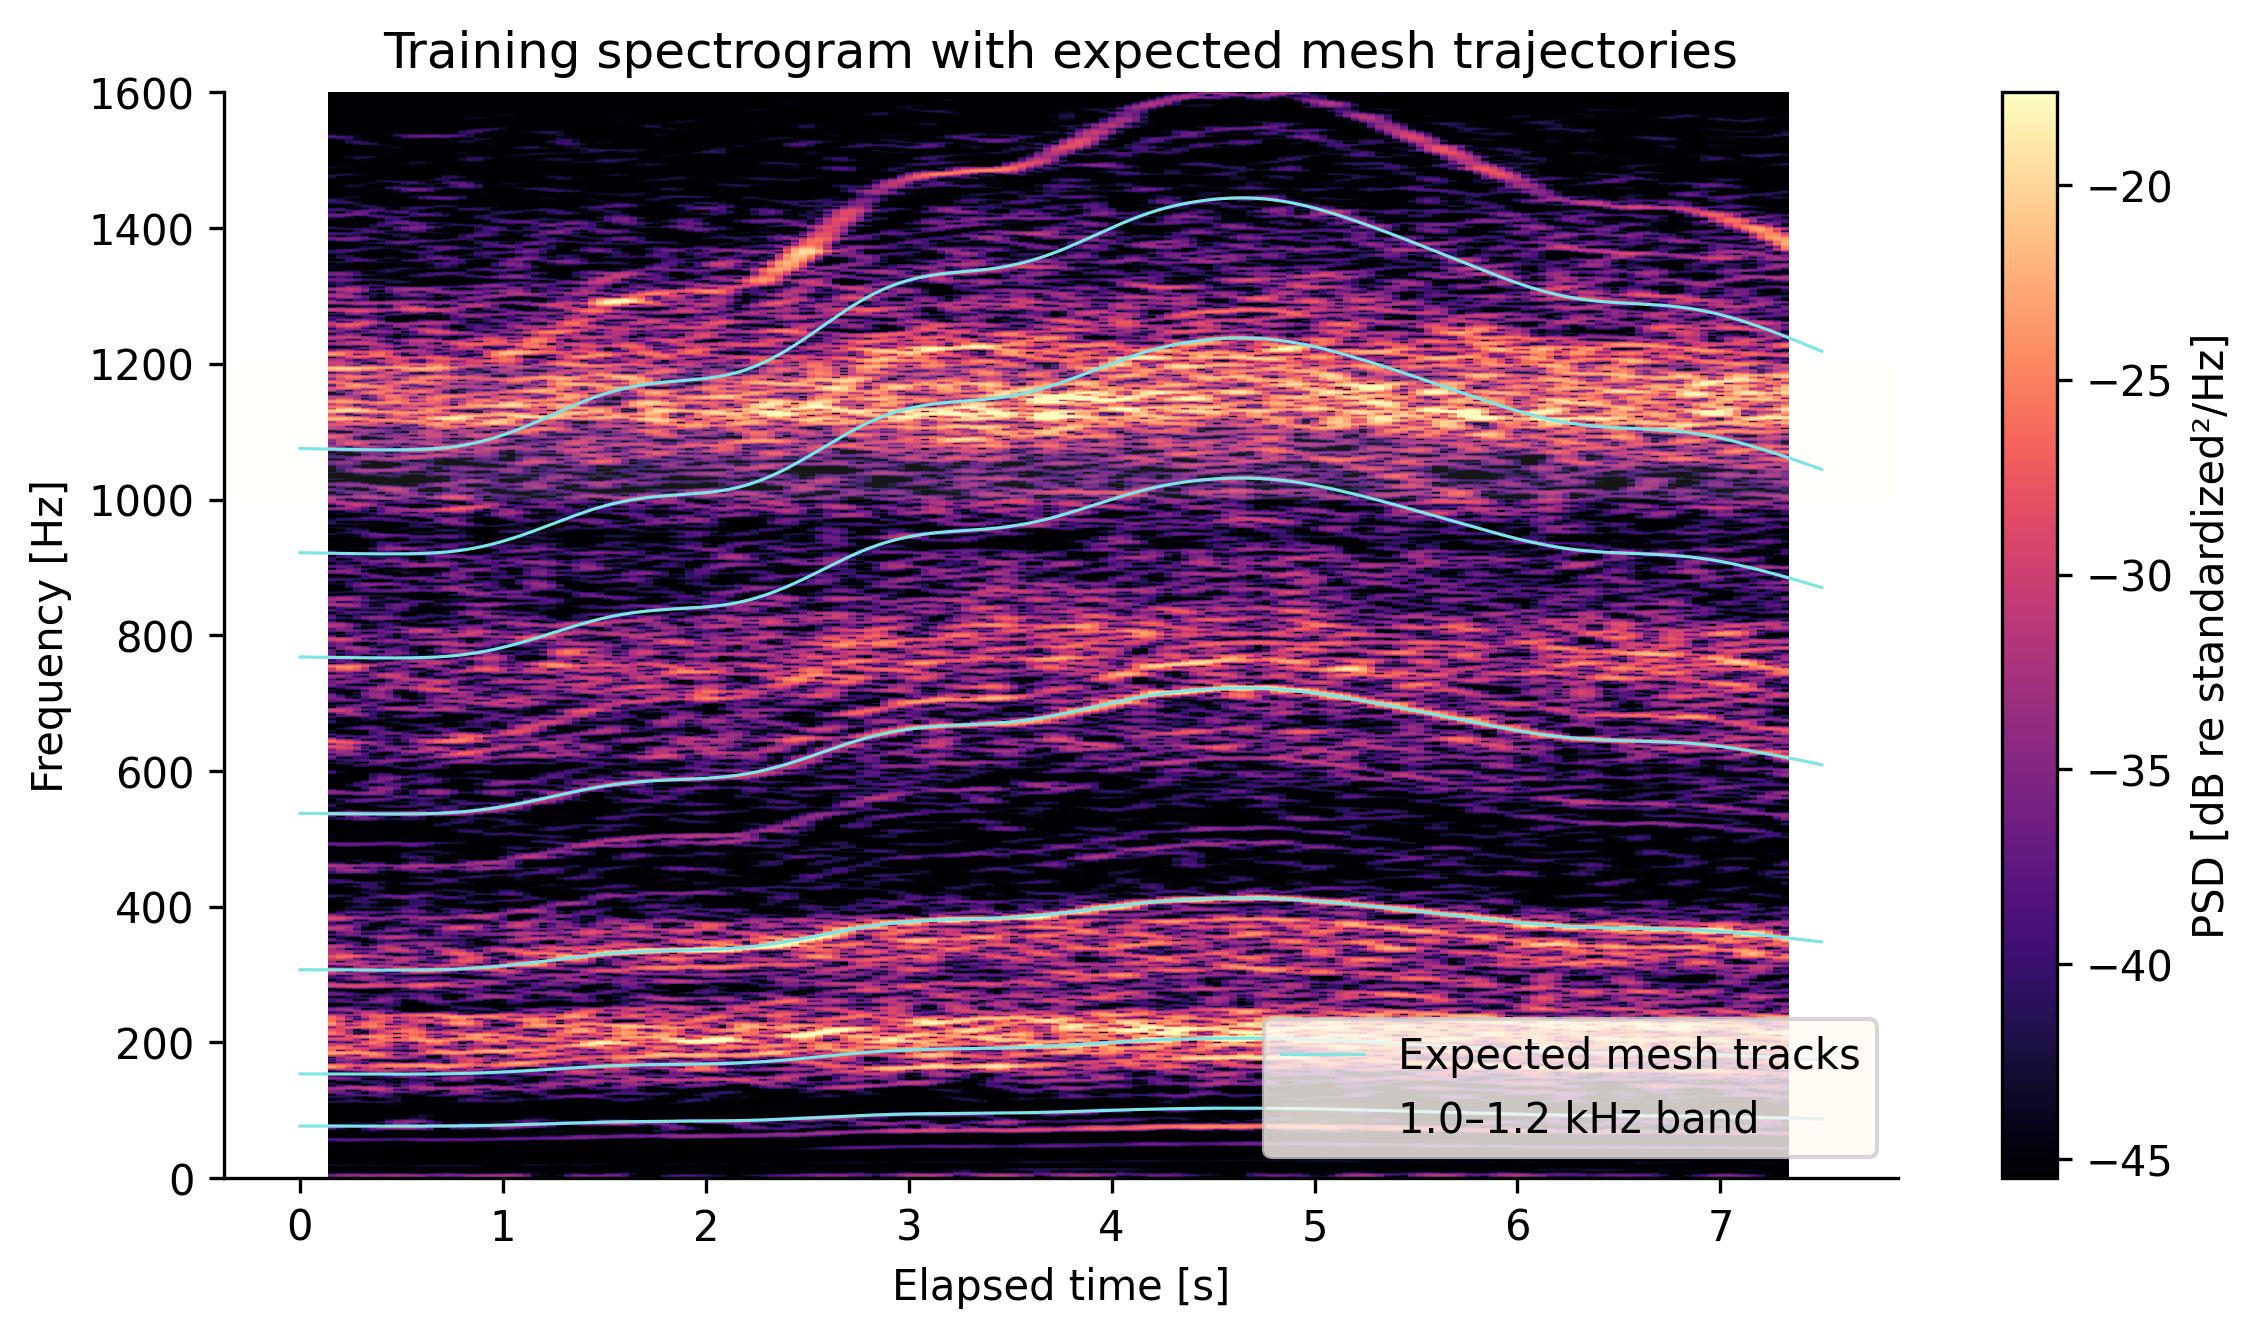

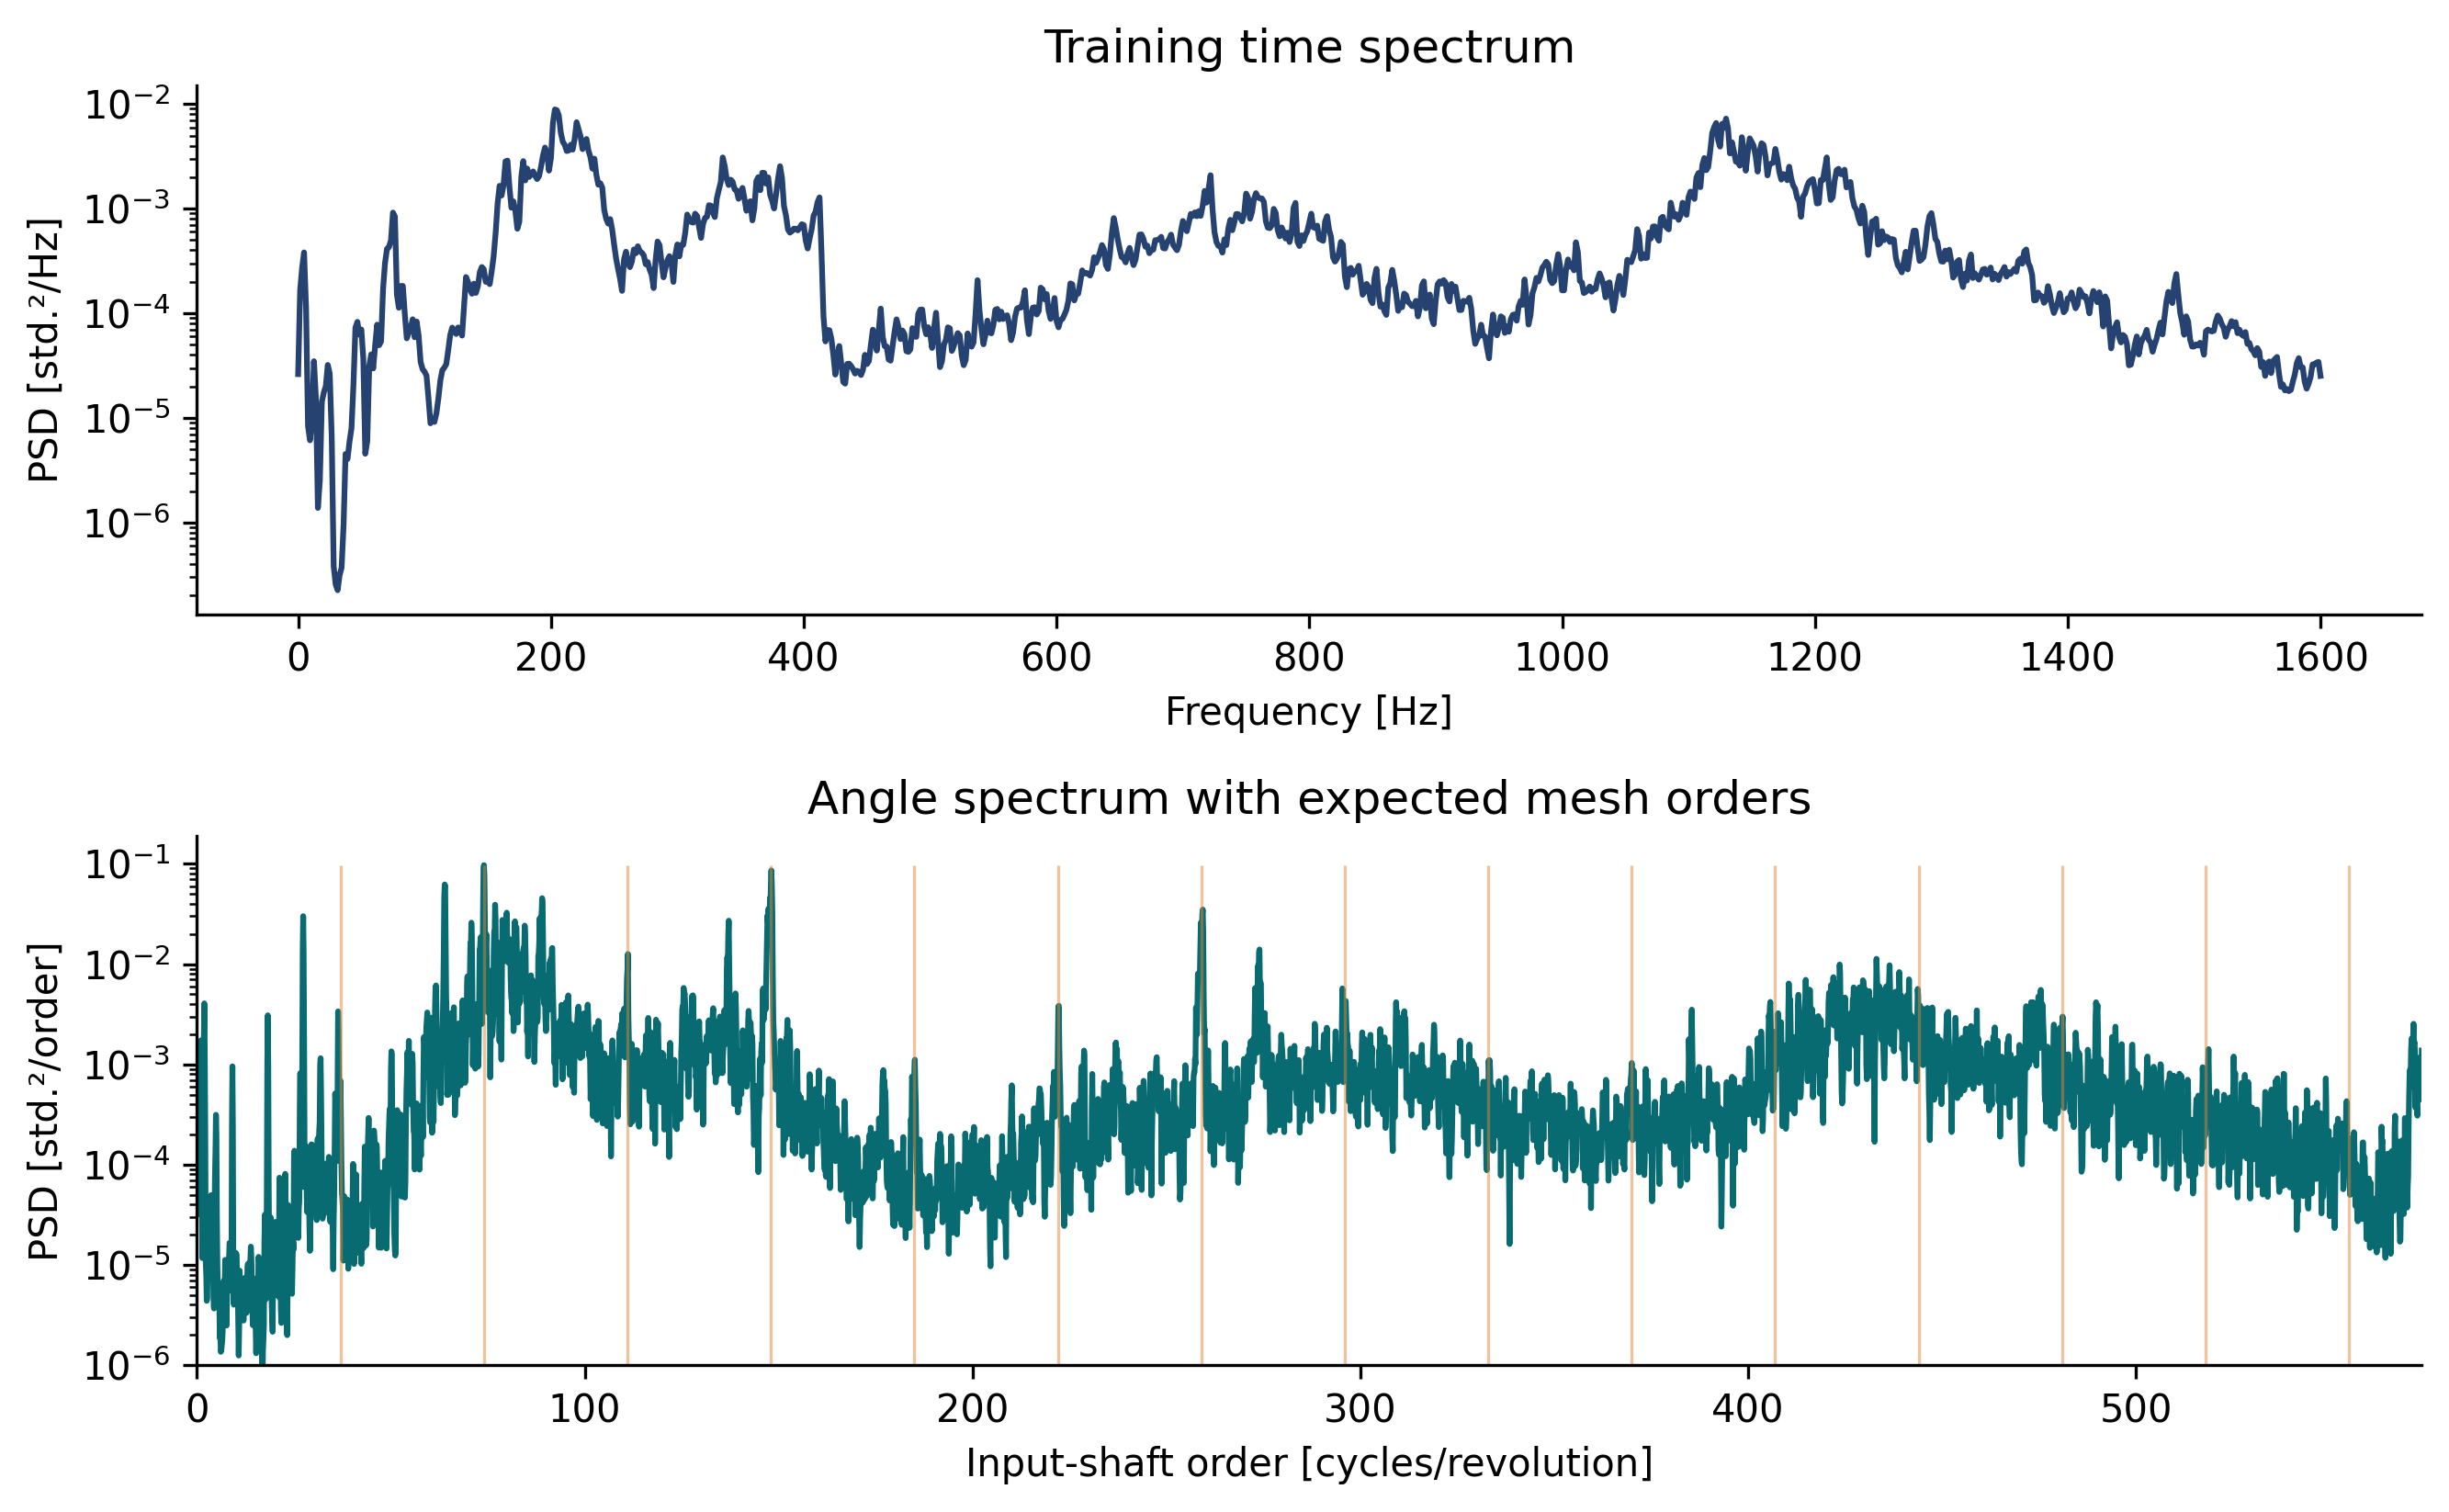

In [2]:
train_eda = evidence("results/eda/summary.json")
columns = ["samples","fs_hz","duration_s","rpm_min","rpm_max",
           "mesh_hz_min","mesh_hz_max","max_mesh_harmonic_at_highest_speed"]
display(pd.Series({k:train_eda[k] for k in columns if k in train_eda}).to_frame("Training only"))
if "rpm_max" in train_eda:
    mesh_at_maximum_speed = 37 * train_eda["rpm_max"] / 60
    harmonic_at_12 = 12 * mesh_at_maximum_speed
    assert harmonic_at_12 < train_eda["fs_hz"] / 2
    print(f"Order 444 at maximum observed training speed: {harmonic_at_12:.2f} Hz")
show_fig("figures/eda/eda_spectrogram.png")
show_fig("figures/eda/eda_orders.png")

Mesh trajectories turn a spectrogram into a quantitative check. The order
spectrum tests recurrence in cycles per revolution; the time spectrum uses
Hertz. Their agreement at one operating point cannot establish a true
structural frequency. Examine speed strata and along-ridge error.

{'constant_speed': {'design_order': 148,
  'estimated_order': 148.00401486585466,
  'absolute_order_error': 0.004014865854657046,
  'angular_points': 36863,
  'complex_quadrature_rmse': 0.00611223273404501,
  'phase_cutoff_exact': True,
  'quadrature_suffix_intervention_max_abs_change': 0.0,
  'passed': True},
 'speed_chirp': {'design_order': 148,
  'estimated_order': 147.9764002262992,
  'absolute_order_error': 0.023599773700794913,
  'angular_points': 37119,
  'complex_quadrature_rmse': 0.00614147022506164,
  'phase_cutoff_exact': True,
  'quadrature_suffix_intervention_max_abs_change': 0.0,
  'passed': True}}

,rpm_lower,rpm_upper_exclusive,direction,frequency_lower_hz,frequency_upper_hz_exclusive,blocks,mean_band_power,std_band_power,mean_spectral_centroid_hz
0,120,135,rising,0,250,5,0.169818,0.056861,734.937345
1,120,135,rising,250,550,5,0.106794,0.039174,734.937345
2,120,135,rising,550,1000,5,0.100409,0.010099,734.937345
3,120,135,rising,1000,1200,5,0.190009,0.026483,734.937345
4,120,135,rising,1200,1600,5,0.099069,0.041553,734.937345
5,120,135,falling,0,250,2,0.187332,0.003327,674.054442
6,120,135,falling,250,550,2,0.058627,0.018044,674.054442
7,120,135,falling,550,1000,2,0.074429,0.020391,674.054442


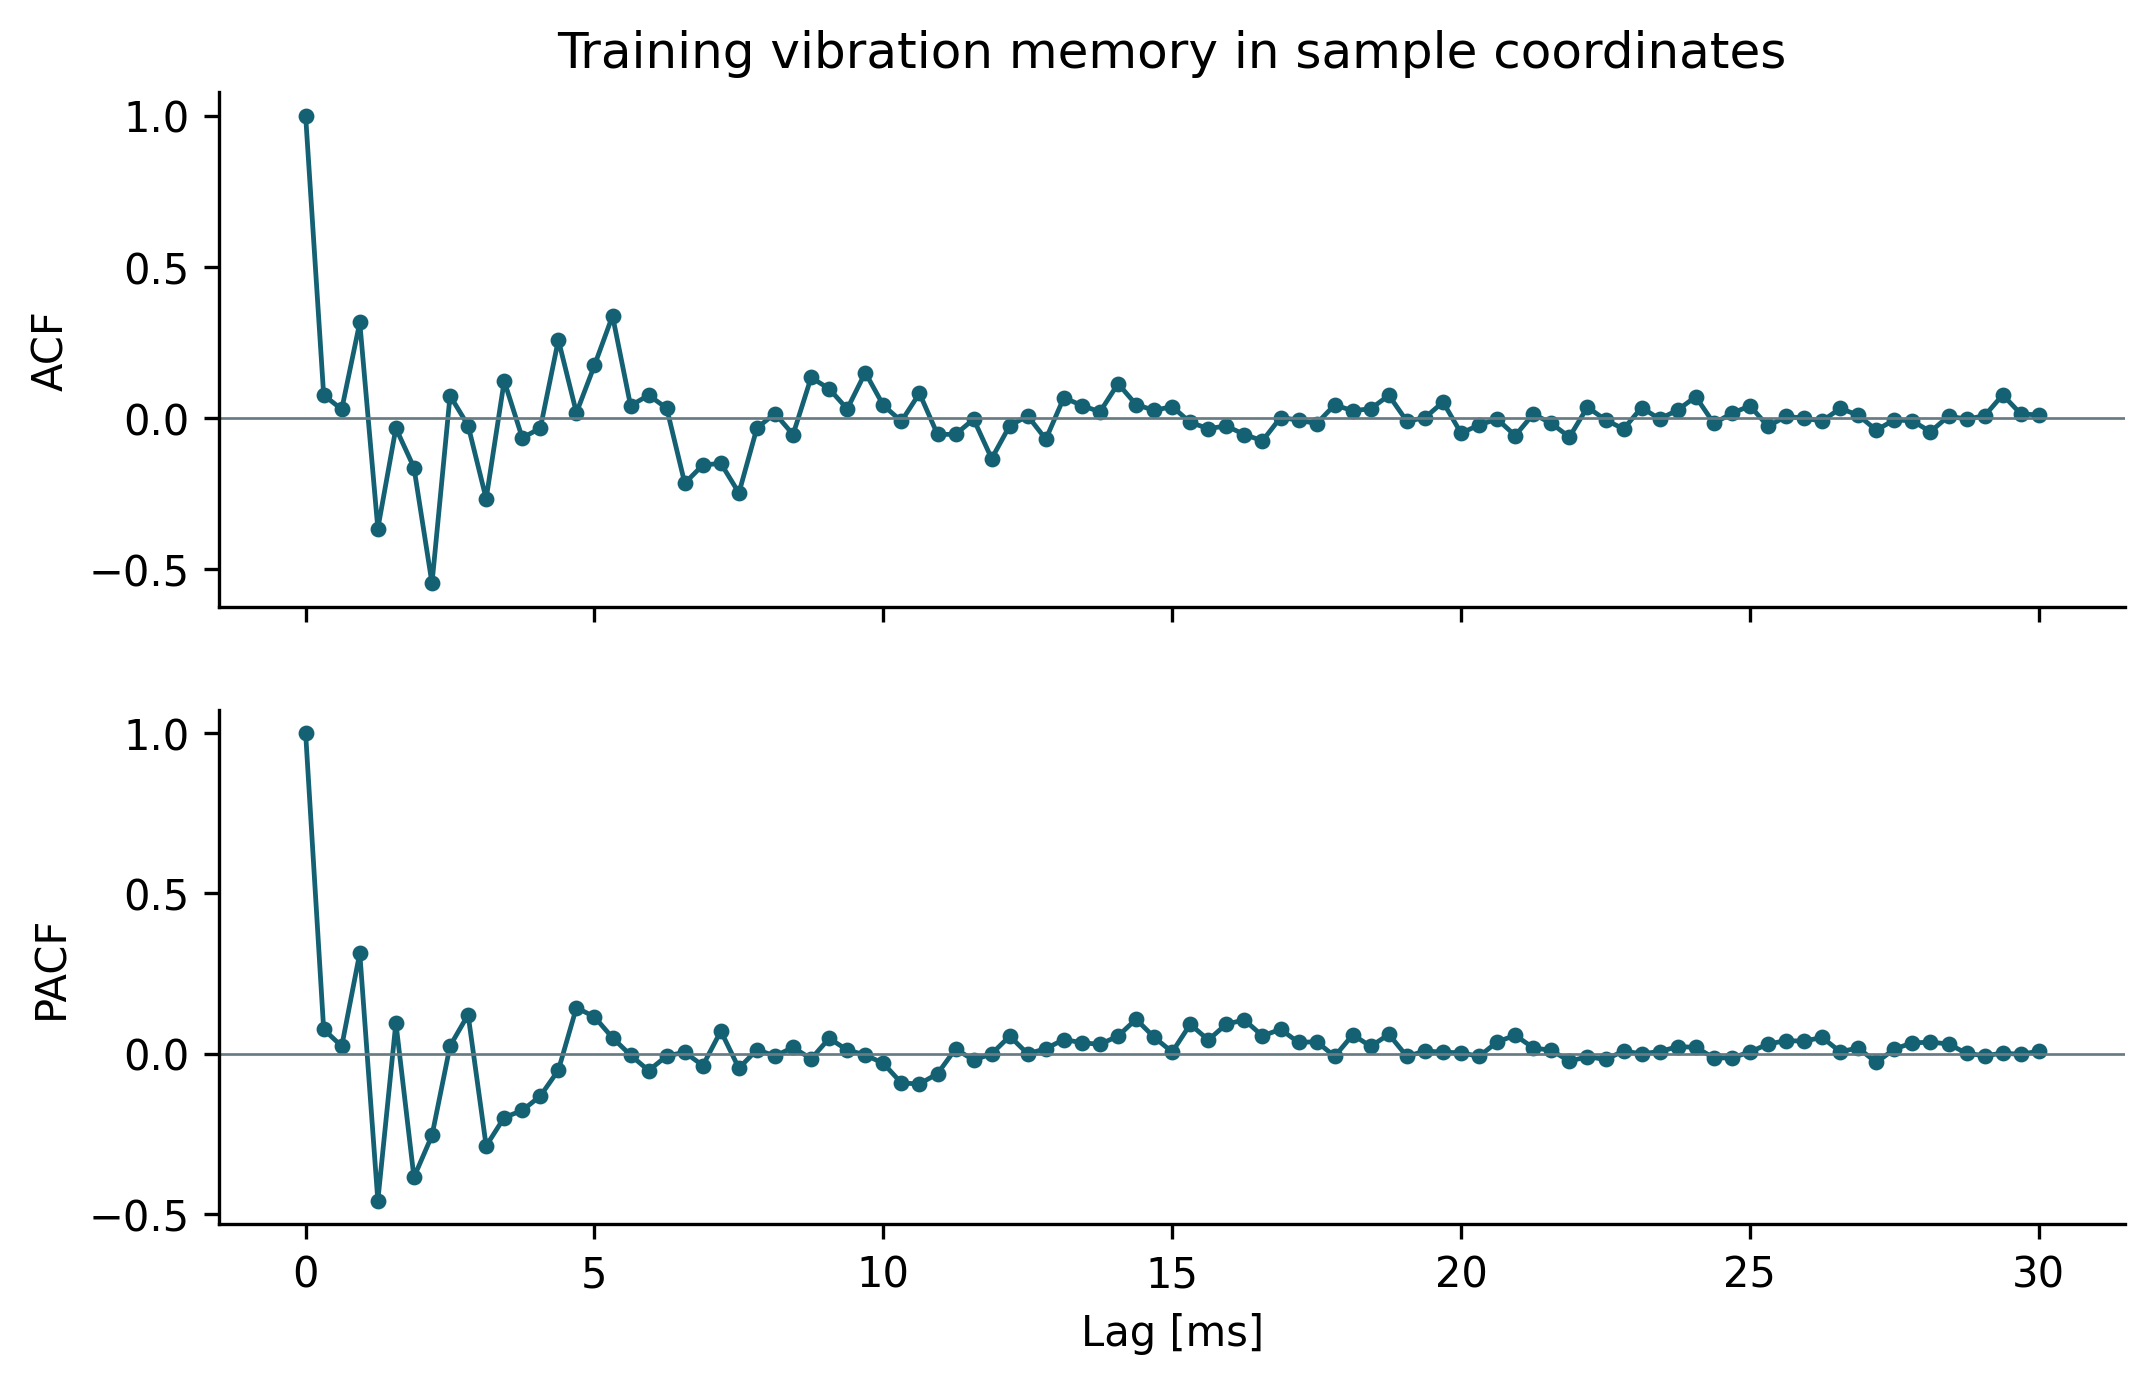

In [3]:
display(evidence("results/eda/synthetic_phase_checks.json"))
regimes = table("results/eda/tables/eda_band_power_by_speed_direction.csv")
if regimes is not None:
    display(regimes.head(8))
show_fig("figures/eda/eda_pacf.png")

,study,fold,score_start,score_stop_exclusive,max_analysis_history,fit_history_guard,speed_lookahead_samples,columns,mse,residual_lag1_acf,squared_residual_rms_rank_corr,causal_feature
0,two_orders_tau_8,1,4800,7200,512,1792,0,78,0.363716,-0.009183,0.039908,True
1,two_orders_tau_32,1,4800,7200,512,1792,0,78,0.376094,0.036798,0.043985,True
2,two_orders_tau_128,1,4800,7200,512,1792,0,78,0.370001,0.033683,0.040253,True
3,lpv_ar24_control,1,4800,7200,512,1792,0,74,0.373844,0.005348,0.043109,True
4,geometry_six_tau_32,1,4800,7200,512,1792,0,86,0.374643,0.046334,0.034666,True
5,fixed_hz_pair_tau_32,1,4800,7200,512,1792,0,78,0.373567,0.003749,0.043139,True
6,two_orders_plus_sidebands,1,4800,7200,512,1792,0,84,0.357446,0.016301,0.049046,True
7,two_orders_structured_degree_2,1,4800,7200,512,1792,0,98,0.360265,-0.005581,0.046200,True
8,two_orders_structured_degree_3,1,4800,7200,512,1792,0,108,0.359783,-0.006951,0.042575,True
9,rpm_lag_32,1,4800,7200,544,1792,0,78,0.376217,0.036435,0.044381,True


,id,feature,mechanism,training_evidence,cost_note,history_samples,starting_grid,failure_mode,recommendation,downstream_experiment_id,causal_status
0,H1,speed and conditional RMS,past RPM schedules gains; local RMS tracks load/speed,RMS/RPM correlation 0.927; causal RMS alone did not improve short LPV screen,O(L),64.0,degree 1–3; RMS 16–128 samples,fit-time load/speed confounding,retain as context,SRC_SPEED,causal with past-only construction and recorded support
1,H2,mesh-aligned lag history,"interpolate at equal past shaft angle, 1/37 turn for one mesh",isolated mesh lag 0.46242 vs short LPV control 0.46153,O(K log N) batch index,670.0,"8–24 nodes/mesh, 4–16 cycles",interpolation bias and pulse absorption,test grouped history,SRC_ANGLE,causal with past-only construction and recorded support
2,H3,focused speed-locked oscillator,demodulate by 2π k u and remodulate at target phase,148 ridge MAE 0.744 Hz; tau32 two-band MSE 0.44560,O(KM) direct FIR or O(K) rolling,512.0,"orders 148,259; decay 8–128 trials",underrepresents other harmonics,recommend focused candidate,SRC_FOCUSED,causal with past-only construction and recorded support
3,H4,broad mesh oscillator,"same rotating history across a first-six, first-twelve or ranked bank",six-band tau32 MSE 0.43537 vs LPV control 0.46153,O(KM) direct FIR or O(K) rolling,512.0,order subsets; decay 8–256; cap prior order near 444,history and dimensionality,recommend geometry candidate,SRC_GEOMETRY,causal with past-only construction and recorded support
4,H5,fixed-Hz state pair,phase from known clock around persistent Hz bands,1080/1125 Hz MSE 0.46152; 31.3% Welch in 1.0–1.2 kHz,O(KM) or O(K) rolling,512.0,off or 1080/1125 Hz,mesh frequency overlap; physical mode unconfirmed,reject as default; retain competing hypothesis,SRC_FIXED_HZ,causal with past-only construction and recorded support
5,H6,shaft and modulation sidebands,1 and 148 ± 1 orders can encode shaft modulation,sidebands MSE 0.42903 vs two-order baseline 0.44560,O(KM) or O(K) rolling,512.0,"none, order one or small symmetric pairs",danger of predicting crack periodicity,require incremental gain and pulse retention,SRC_SIDEBANDS,causal with past-only construction and recorded support
6,H7,structured polynomial interactions,local gain from RMS×lag and speed×quadrature,degree2 MSE 0.43819; degree3 0.43803,O(P),512.0,"degrees 1–3, screened interactions",instability outside experienced amplitude range,compare low degrees with shrinkage,SRC_LIBRARY,causal with past-only construction and recorded support
7,H8,causal innovation memory,lagged prediction errors of previous observed targets,residual ACF and conditional residual/RMS rank correlation measured by fold,O(P),NaN,proxy AR 64–384 and errors 8–48,fault dilution and state contamination,fit both stages within guarded segments,SRC_INNOVATION,causal with past-only construction and recorded support


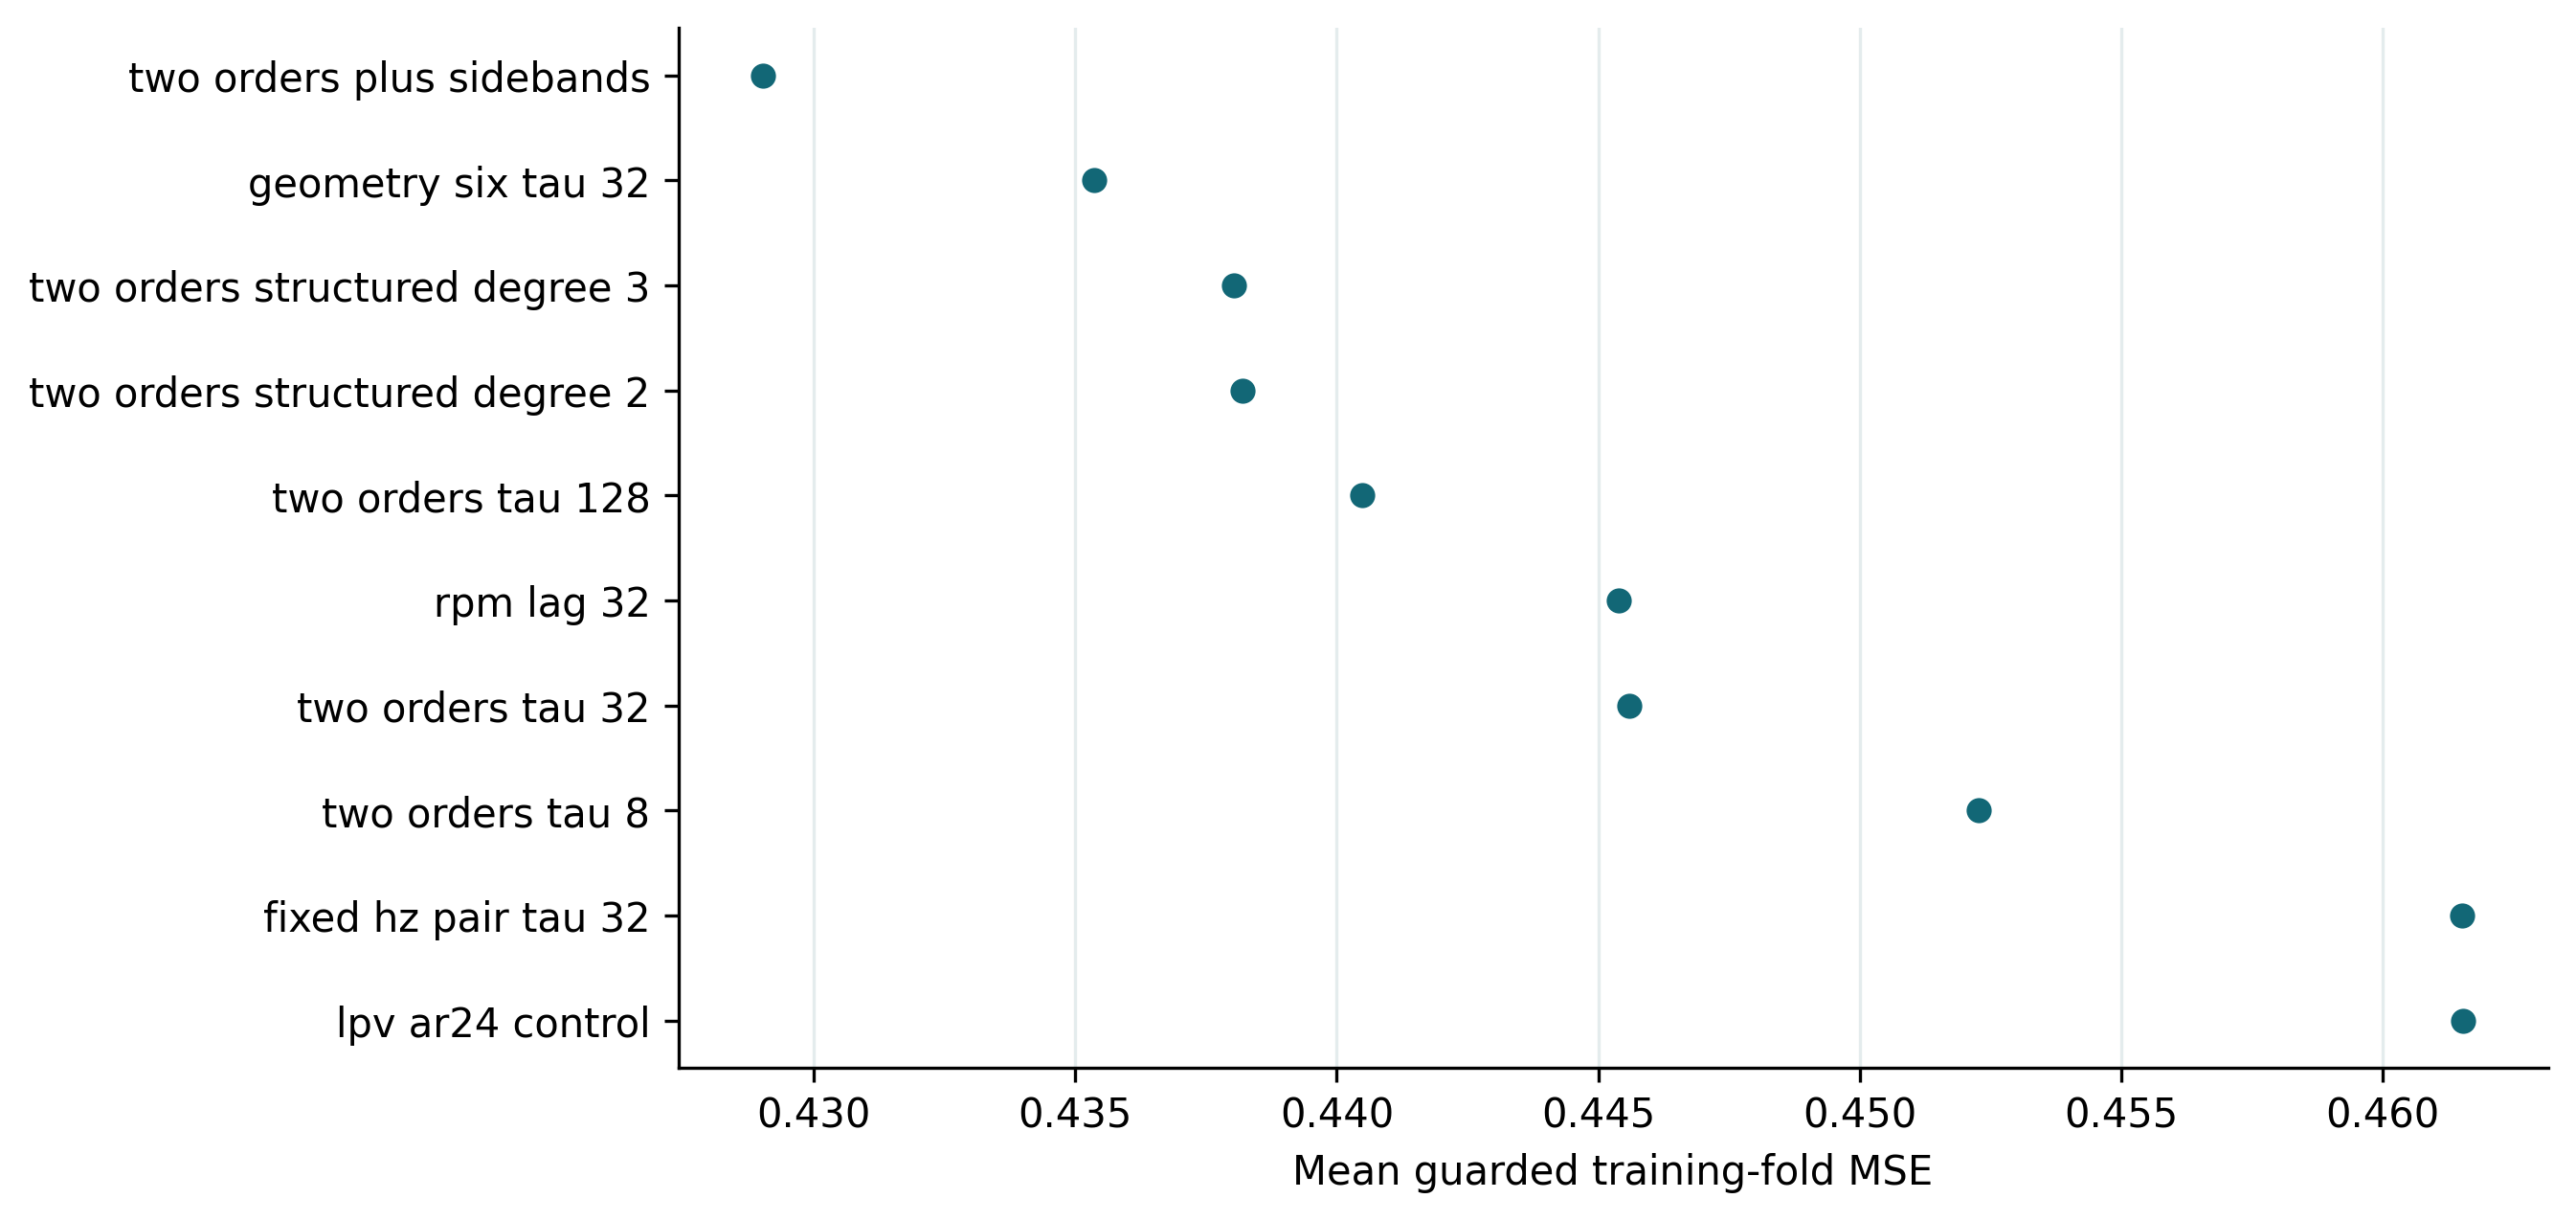

In [4]:
screen = table("results/eda/tables/src_feature_screen.csv")
if screen is not None:
    display(screen.head(16))
ideas = table("results/eda_feature_hypotheses.csv")
if ideas is not None:
    display(ideas.head(20))
show_fig("figures/eda/eda_feature_decisions.png")

### Interpretation and limits

Order-aligned and angular features merit controlled tuning. A measured waveform
can exhibit a fixed-frequency band even when a candidate pair offers little
incremental prediction value. Cubic expansion should earn its additional columns
on held-out fold blocks. The synthetic chirp validates units and state indexing;
it makes no claim about defect sensitivity in the rig.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).